# Tổng quan mẫu NHANES 2015–2018

## Đọc dữ liệu

Đọc bảng NHANES đã chuẩn bị từ Parquet. Số đếm và tỷ lệ trong notebook chưa áp trọng số khảo sát, không đại diện cho tỷ lệ bệnh trong dân số.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

nhanes = pd.read_parquet(Path("../data/processed/nhanes_2015_2018.parquet"))
input_cols = ["age", "sex", "race_ethnicity", "bmi", "smoking_status",
              "physical_activity", "heart_attack", "stroke"]

Kiểm tra số dòng, `SEQN`, kiểu dữ liệu và nhãn bệnh.

In [2]:
assert nhanes["SEQN"].notna().all() and nhanes["SEQN"].is_unique
assert nhanes["diabetes_label"].notna().all()
assert nhanes["diabetes_label"].isin([0, 1]).all()
assert nhanes["diabetes_label"].dtype == pd.Int64Dtype()
pd.Series({
    "Số người": nhanes.shape[0], "Số cột": nhanes.shape[1],
    "SEQN duy nhất": nhanes["SEQN"].nunique(),
    "SEQN thiếu": nhanes["SEQN"].isna().sum(),
    "SEQN trùng": nhanes["SEQN"].duplicated().sum(),
    "Nhãn thiếu": nhanes["diabetes_label"].isna().sum(),
}, name="Kết quả").to_frame()

,Kết quả
Số người,10832
Số cột,16
SEQN duy nhất,10832
SEQN thiếu,0
SEQN trùng,0
Nhãn thiếu,0


In [3]:
nhanes.dtypes.astype(str).rename("dtype").to_frame()

,dtype
age,float64
sex,Int64
race_ethnicity,string
bmi,float64
smoking_status,string
physical_activity,Int64
heart_attack,Int64
stroke,Int64
diabetes_label,Int64
SEQN,float64


In [4]:
nhanes["diabetes_label"].value_counts(dropna=False).sort_index().rename("Số người").to_frame()

,Số người
diabetes_label,
0,8558
1,2274


Mẫu có 10.832 người, không trùng `SEQN` và không thiếu nhãn.

## Phân bố nhãn

Đếm nhãn 0/1 và tính tỷ lệ nhãn 1 theo chu kỳ.

In [5]:
cycle_summary = pd.crosstab(nhanes["cycle"], nhanes["diabetes_label"])
cycle_summary = cycle_summary.reindex(columns=[0, 1], fill_value=0).rename(columns={0: "Nhãn 0", 1: "Nhãn 1"})
cycle_summary.columns.name = None
cycle_summary.insert(0, "Số người", cycle_summary.sum(axis=1))
cycle_summary["Tỷ lệ dương (%)"] = cycle_summary["Nhãn 1"] / cycle_summary["Số người"] * 100
cycle_summary.round({"Tỷ lệ dương (%)": 2})

,Số người,Nhãn 0,Nhãn 1,Tỷ lệ dương (%)
cycle,,,,
2015-2016,5502,4397,1105,20.08
2017-2018,5330,4161,1169,21.93


Tỷ lệ nhãn 1 trong mẫu tăng từ 20,08% ở 2015–2016 lên 21,93% ở 2017–2018; chưa thể suy ra tỷ lệ bệnh trong dân số thay đổi.

## Giá trị thiếu

Đếm số thiếu và tỷ lệ thiếu của 8 đầu vào trên toàn mẫu.

In [6]:
missing_summary = pd.DataFrame({
    "Số thiếu": nhanes[input_cols].isna().sum(),
    "Tỷ lệ thiếu (%)": nhanes[input_cols].isna().mean() * 100,
})
missing_summary.index.name = "Đầu vào"
missing_summary.round({"Tỷ lệ thiếu (%)": 2})

,Số thiếu,Tỷ lệ thiếu (%)
Đầu vào,,
age,0,0.00
sex,0,0.00
race_ethnicity,0,0.00
bmi,228,2.10
smoking_status,9,0.08
physical_activity,25,0.23
heart_attack,499,4.61
stroke,495,4.57


Hai biến tiền sử nhồi máu cơ tim và đột quỵ thiếu nhiều nhất, có cả người 18–19 tuổi không được hỏi. Giữ các trường hợp này là NA, không chuyển thành Không.

Vẽ số người nhãn 0/1 của hai chu kỳ gộp lại. Nhãn 0 chỉ phản ánh quy tắc quan sát đã chọn, không khẳng định chắc chắn không mắc bệnh.

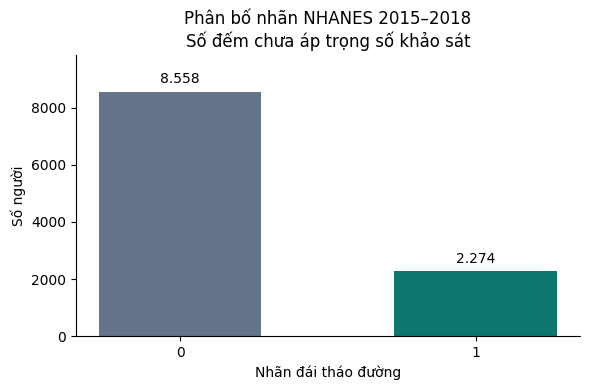

In [7]:
label_counts = nhanes["diabetes_label"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["0", "1"], label_counts.to_numpy(), color=["#64748b", "#0f766e"], width=0.55)
ax.bar_label(bars, labels=[f"{int(n):,}".replace(",", ".") for n in label_counts], padding=4)
ax.set(xlabel="Nhãn đái tháo đường", ylabel="Số người",
       title="Phân bố nhãn NHANES 2015–2018\nSố đếm chưa áp trọng số khảo sát",
       ylim=(0, label_counts.max() * 1.15))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Nhãn 1 có 2.274 người, chiếm khoảng 21% mẫu.

## Tuổi và BMI

Mô tả tuổi và BMI trên toàn mẫu, chưa tách theo nhãn. Bỏ qua BMI thiếu khi vẽ, giữ nguyên các dòng và giá trị cao.

In [2]:
nhanes[["age", "bmi"]].describe()

,age,bmi
count,10832.00000,10604.000000
mean,49.35312,29.596709
std,18.51775,7.260485
min,18.00000,14.200000
25%,33.00000,24.500000
50%,50.00000,28.400000
75%,64.00000,33.400000
max,80.00000,86.200000


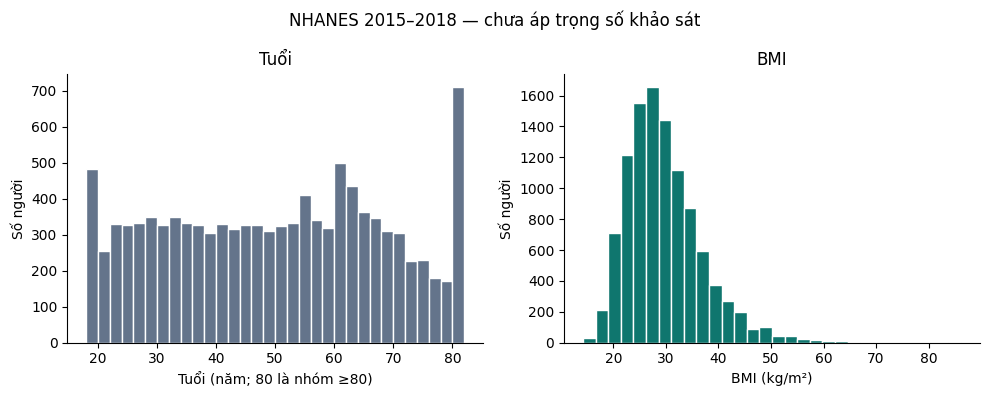

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(nhanes["age"], bins=range(18, 83, 2), color="#64748b", edgecolor="white")
axes[0].set(title="Tuổi", xlabel="Tuổi (năm; 80 là nhóm ≥80)", ylabel="Số người")
axes[1].hist(nhanes["bmi"].dropna(), bins=30, color="#0f766e", edgecolor="white")
axes[1].set(title="BMI", xlabel="BMI (kg/m²)", ylabel="Số người")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("NHANES 2015–2018 — chưa áp trọng số khảo sát")
fig.tight_layout()
plt.show()

In [4]:
age_80_summary = pd.DataFrame({
    "Nhóm tuổi": ["≥80 tuổi (age = 80)"],
    "Số người": [int(nhanes["age"].eq(80).sum())],
    "Tỷ lệ trong mẫu (%)": [nhanes["age"].eq(80).mean() * 100],
})
age_80_summary.round({"Tỷ lệ trong mẫu (%)": 2})

,Nhóm tuổi,Số người,Tỷ lệ trong mẫu (%)
0,≥80 tuổi (age = 80),711,6.56


Tuổi trung vị là 50; có 711 người (6,56%) thuộc nhóm ≥80 tuổi, được ghi chung là 80.

BMI trung vị là 28,4 kg/m², cao nhất 86,2 kg/m²; chưa có căn cứ coi giá trị cao là lỗi. Histogram BMI dùng 10.604 giá trị quan sát được, còn dữ liệu vẫn giữ đủ 10.832 người.

## Các biến phân loại

Tính tỷ lệ trên toàn bộ 10.832 người, kể cả nhóm Thiếu. Chỉ đổi tên nhóm khi hiển thị, giữ nguyên mã trong dữ liệu.

In [2]:
category_labels = {
    "sex": {1: "Nam", 2: "Nữ"},
    "race_ethnicity": {
        "White NH": "Da trắng, không Hispanic",
        "Black NH": "Da đen, không Hispanic",
        "Hispanic": "Hispanic", "Other": "Khác",
    },
    "smoking_status": {
        "never": "Chưa hút đủ 100 điếu", "former": "Đã bỏ", "current": "Đang hút",
    },
    "physical_activity": {0: "Chưa đạt ngưỡng", 1: "Đạt ngưỡng"},
    "heart_attack": {0: "Không", 1: "Có"},
    "stroke": {0: "Không", 1: "Có"},
}
assert len(nhanes) == 10832
category_rows = []
for variable, groups in category_labels.items():
    assert nhanes[variable].dropna().isin(groups).all()
    for value, label in groups.items():
        count = int(nhanes[variable].eq(value).sum())
        category_rows.append((variable, label, count, count / len(nhanes) * 100))
    missing = int(nhanes[variable].isna().sum())
    if missing:
        category_rows.append((variable, "Thiếu", missing, missing / len(nhanes) * 100))
categorical_summary = pd.DataFrame(
    category_rows, columns=["Biến", "Nhóm", "Số người", "Tỷ lệ (%)"]
)
assert categorical_summary.groupby("Biến")["Số người"].sum().eq(len(nhanes)).all()
assert (categorical_summary.groupby("Biến")["Tỷ lệ (%)"].sum() - 100).abs().lt(1e-10).all()
categorical_summary.round({"Tỷ lệ (%)": 2})

,Biến,Nhóm,Số người,Tỷ lệ (%)
0,sex,Nam,5222,48.21
1,sex,Nữ,5610,51.79
2,race_ethnicity,"Da trắng, không Hispanic",3633,33.54
3,race_ethnicity,"Da đen, không Hispanic",2359,21.78
4,race_ethnicity,Hispanic,2961,27.34
5,race_ethnicity,Khác,1879,17.35
6,smoking_status,Chưa hút đủ 100 điếu,6418,59.25
7,smoking_status,Đã bỏ,2471,22.81
8,smoking_status,Đang hút,1934,17.85
9,smoking_status,Thiếu,9,0.08


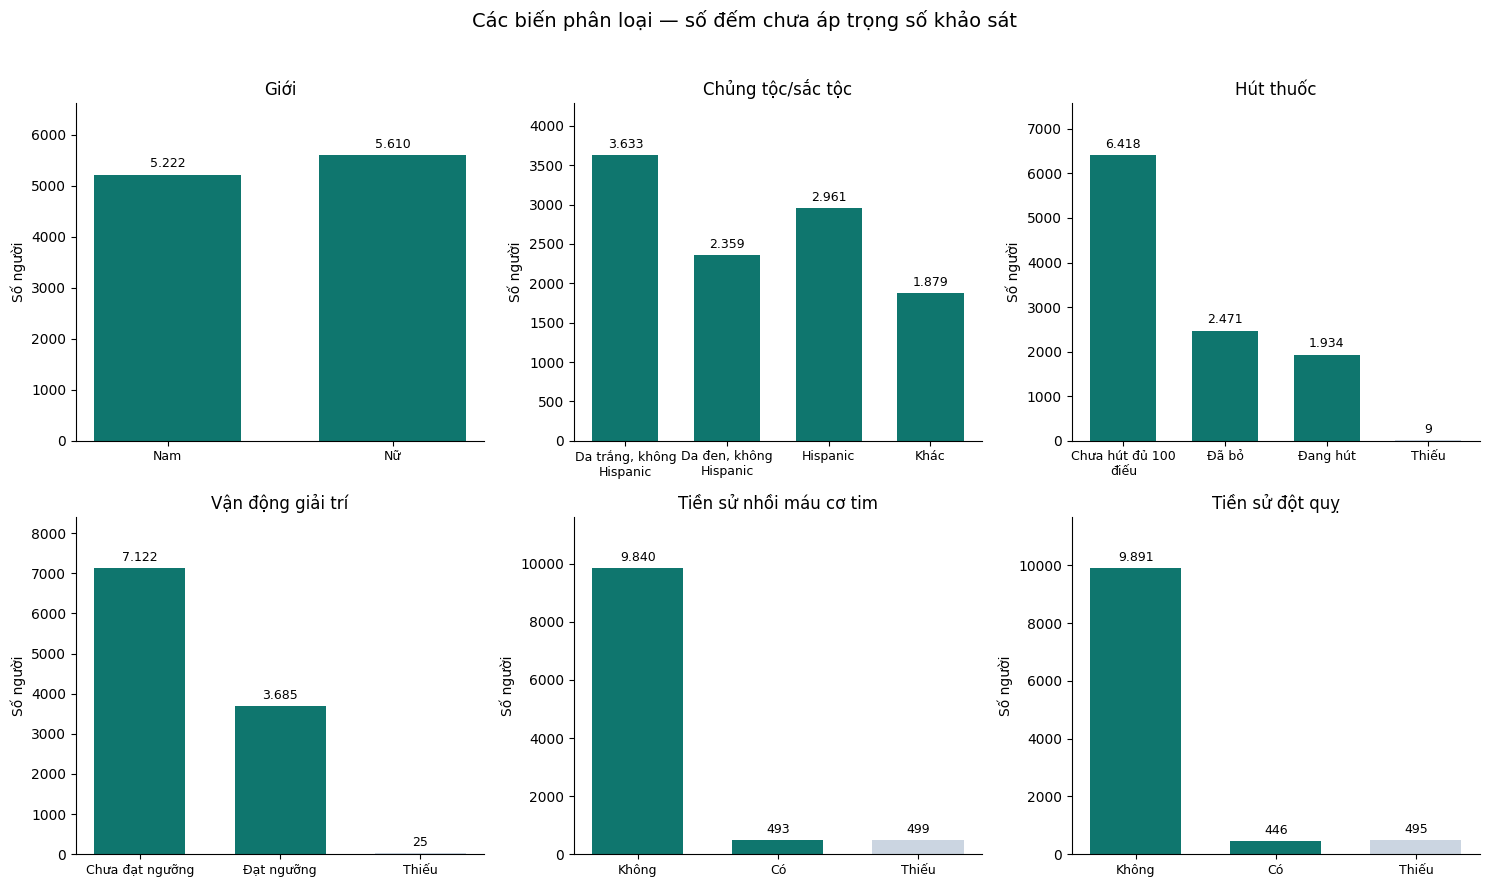

In [3]:
from textwrap import fill

category_titles = {
    "sex": "Giới", "race_ethnicity": "Chủng tộc/sắc tộc",
    "smoking_status": "Hút thuốc", "physical_activity": "Vận động giải trí",
    "heart_attack": "Tiền sử nhồi máu cơ tim", "stroke": "Tiền sử đột quỵ",
}
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (variable, title) in zip(axes.flat, category_titles.items()):
    group = categorical_summary.loc[categorical_summary["Biến"].eq(variable)]
    colors = ["#cbd5e1" if label == "Thiếu" else "#0f766e" for label in group["Nhóm"]]
    bars = ax.bar(range(len(group)), group["Số người"], color=colors, width=0.65)
    ax.set_xticks(range(len(group)), [fill(label, width=18) for label in group["Nhóm"]])
    ax.bar_label(bars, labels=[f"{int(n):,}".replace(",", ".") for n in group["Số người"]], padding=3, fontsize=9)
    ax.set(title=title, ylabel="Số người", ylim=(0, group["Số người"].max() * 1.18))
    ax.tick_params(axis="x", labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Các biến phân loại — số đếm chưa áp trọng số khảo sát", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

Nữ chiếm 51,79%; nhóm da trắng không Hispanic đông nhất. Có 3.685 người (34,02%) đạt ≥150 phút vận động giải trí tương đương cường độ vừa/tuần.

## Đặc điểm theo nhãn bệnh

Mô tả tuổi, BMI theo nhãn và tính tỷ lệ nhãn 1 trong từng nhóm phân loại. Giữ nhóm Thiếu riêng; các so sánh chưa điều chỉnh yếu tố khác.

In [2]:
continuous_by_label = pd.concat({
    variable: nhanes.groupby("diabetes_label")[variable].agg(**{
        "Số quan sát": "count",
        "Trung vị": "median",
        "Q1": lambda s: s.quantile(0.25),
        "Q3": lambda s: s.quantile(0.75),
        "Số thiếu": lambda s: s.isna().sum(),
    })
    for variable in ["age", "bmi"]
}, names=["Biến"])
for variable in ["age", "bmi"]:
    counts = continuous_by_label.loc[variable, "Số quan sát"] + continuous_by_label.loc[variable, "Số thiếu"]
    pd.testing.assert_series_equal(counts, nhanes.groupby("diabetes_label").size(), check_names=False)
continuous_by_label

Số quan sát  Trung vị    Q1    Q3  Số thiếu
Biến diabetes_label                                             
age  0                      8558      45.0  30.0  61.0         0
     1                      2274      63.0  53.0  72.0         0
bmi  0                      8456      27.8  24.0  32.4       102
     1                      2148      31.3  27.3  36.3       126

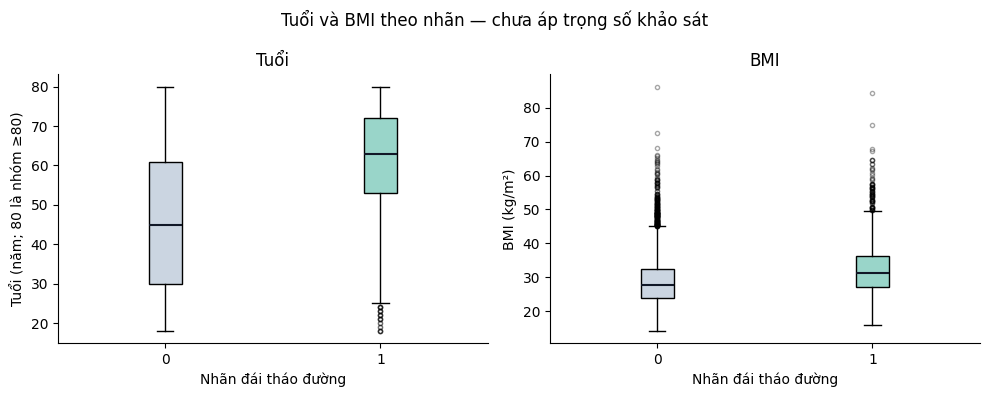

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, variable, title, unit in zip(
    axes, ["age", "bmi"], ["Tuổi", "BMI"], ["Tuổi (năm; 80 là nhóm ≥80)", "BMI (kg/m²)"]
):
    # Chỉ bỏ giá trị thiếu trong mảng vẽ, không thay đổi bảng dữ liệu.
    values = [nhanes.loc[nhanes["diabetes_label"].eq(label), variable].dropna().to_numpy(dtype=float)
              for label in [0, 1]]
    boxes = ax.boxplot(values, positions=[0, 1], showfliers=True, patch_artist=True,
                       flierprops={"marker": "o", "markersize": 3, "alpha": 0.35},
                       medianprops={"color": "#111827", "linewidth": 1.5})
    for box, color in zip(boxes["boxes"], ["#cbd5e1", "#99d5c9"]):
        box.set_facecolor(color)
    ax.set_xticks([0, 1], ["0", "1"])
    ax.set(title=title, xlabel="Nhãn đái tháo đường", ylabel=unit)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Tuổi và BMI theo nhãn — chưa áp trọng số khảo sát")
fig.tight_layout()
plt.show()

Nhóm nhãn 1 có trung vị tuổi và BMI là 63 tuổi và 31,3 kg/m², cao hơn nhóm nhãn 0 (45 tuổi và 27,8 kg/m²). Boxplot giữ các điểm ngoài râu; thống kê và biểu đồ bỏ qua giá trị thiếu nhưng không xóa dòng khỏi dữ liệu.

In [4]:
category_label_rows = []
for variable, groups in category_labels.items():
    assert nhanes[variable].dropna().isin(groups).all()
    for value, label in groups.items():
        mask = nhanes[variable].eq(value).fillna(False)
        total = int(mask.sum())
        positives = int(nhanes.loc[mask, "diabetes_label"].eq(1).sum())
        category_label_rows.append((variable, label, total, positives,
                                   positives / total * 100 if total else float("nan")))
    missing_mask = nhanes[variable].isna()
    if missing_mask.any():
        total = int(missing_mask.sum())
        positives = int(nhanes.loc[missing_mask, "diabetes_label"].eq(1).sum())
        category_label_rows.append((variable, "Thiếu", total, positives, positives / total * 100))
category_by_label = pd.DataFrame(category_label_rows, columns=[
    "Biến", "Nhóm", "Tổng số người", "Số nhãn 1", "Tỷ lệ nhãn 1 trong mẫu (%)"
])
assert category_by_label.groupby("Biến")["Tổng số người"].sum().eq(10832).all()
assert category_by_label.groupby("Biến")["Số nhãn 1"].sum().eq(2274).all()
category_by_label.round({"Tỷ lệ nhãn 1 trong mẫu (%)": 2})

,Biến,Nhóm,Tổng số người,Số nhãn 1,Tỷ lệ nhãn 1 trong mẫu (%)
0,sex,Nam,5222,1186,22.71
1,sex,Nữ,5610,1088,19.39
2,race_ethnicity,"Da trắng, không Hispanic",3633,668,18.39
3,race_ethnicity,"Da đen, không Hispanic",2359,540,22.89
4,race_ethnicity,Hispanic,2961,693,23.40
5,race_ethnicity,Khác,1879,373,19.85
6,smoking_status,Chưa hút đủ 100 điếu,6418,1216,18.95
7,smoking_status,Đã bỏ,2471,733,29.66
8,smoking_status,Đang hút,1934,323,16.70
9,smoking_status,Thiếu,9,2,22.22


Tỷ lệ nhãn 1 trong mẫu là 24,74% ở nhóm chưa đạt ngưỡng vận động và 13,70% ở nhóm đạt ngưỡng. Khác biệt này không cho biết quan hệ nhân quả hay tầm quan trọng của biến với mô hình.